In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model



In [4]:
(X_train, _), (X_test, _) = mnist.load_data()

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [5]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))

print(X_train.shape)
print(X_test.shape)


(60000, 784)
(10000, 784)


In [6]:
encoding_dim = 32
input_img = Input(shape=(784,))
encoded = Dense(128, activation="relu")(input_img)
encoded = Dense(64, activation="relu")(encoded)
latent = Dense(encoding_dim, activation="relu")(encoded)
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(784, activation="sigmoid")(decoded)
autoencoder = Model(input_img, decoded)
encoder = Model(input_img, latent)
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)
autoencoder.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 784)]             0         
                                                                 
 dense (Dense)               (None, 128)               100480    
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 64)                2112      
                                                                 
 dense_4 (Dense)             (None, 128)               8320      
                                                                 
 dense_5 (Dense)             (None, 784)               101136

In [7]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test, X_test)
)


Epoch 1/10
235/235 [==============================] - 4s 7ms/step - loss: 0.2372 - val_loss: 0.1628
Epoch 2/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1494 - val_loss: 0.1369
Epoch 3/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1321 - val_loss: 0.1249
Epoch 4/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1219 - val_loss: 0.1167
Epoch 5/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1155 - val_loss: 0.1116
Epoch 6/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1106 - val_loss: 0.1079
Epoch 7/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1071 - val_loss: 0.1046
Epoch 8/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1047 - val_loss: 0.1023
Epoch 9/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1027 - val_loss: 0.1008
Epoch 10/10
235/235 [==============================] - 1s 6ms/step - loss: 0.1009 - val_loss: 0.0989

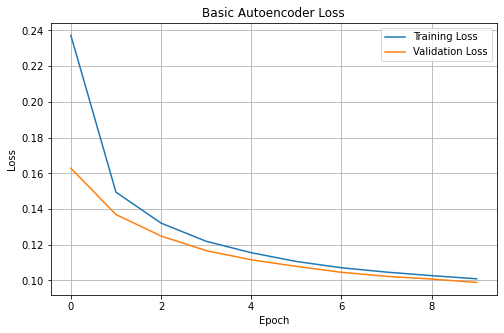

In [8]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic Autoencoder Loss")
plt.legend()
plt.grid(True)
plt.show()


In [9]:
decoded_imgs = autoencoder.predict(X_test)

313/313 [==============================] - 1s 1ms/step


In [10]:
latent_features = encoder.predict(X_test)
print("Latent Feature Shape:", latent_features.shape)


313/313 [==============================] - 0s 1ms/step
Latent Feature Shape: (10000, 32)


In [11]:
print("Original Dimension :",784)
print("Compressed Dimension :",encoding_dim)
print("Compression Ratio :",784/encoding_dim)


Original Dimension : 784
Compressed Dimension : 32
Compression Ratio : 24.5


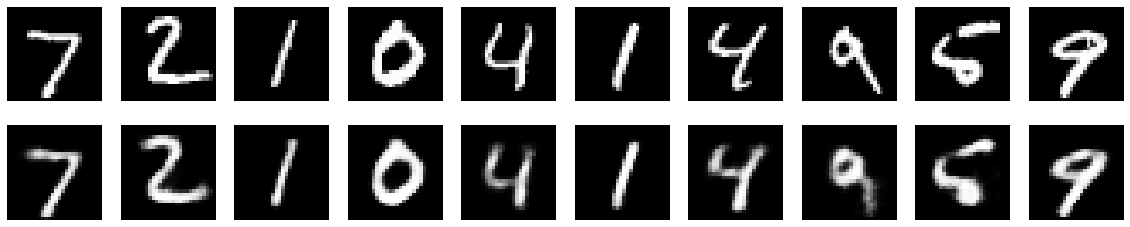

In [12]:
n = 10
plt.figure(figsize=(20,4))
for i in range(n):
    # Original
    ax = plt.subplot(2,n,i+1)
    plt.imshow(X_test[i].reshape(28,28), cmap="gray")
    plt.axis("off")
    # Reconstruction
    ax = plt.subplot(2,n,i+1+n)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap="gray")
    plt.axis("off")
plt.show()


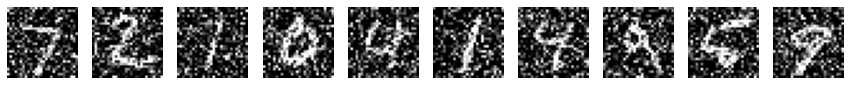

In [13]:
import numpy as np

noise_factor = 0.5

X_train_noisy = X_train + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=X_train.shape)
X_test_noisy = X_test + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=X_test.shape
)
# Keep pixel values between 0 and 1
X_train_noisy = np.clip(X_train_noisy, 0., 1.)
X_test_noisy = np.clip(X_test_noisy, 0., 1.)
plt.figure(figsize=(15,3))
for i in range(10):
    ax = plt.subplot(1,10,i+1)
    plt.imshow(X_test_noisy[i].reshape(28,28), cmap="gray")
    plt.axis("off")

plt.show()


In [14]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
encoding_dim = 32
input_img = Input(shape=(784,))
# Encoder
x = Dense(128, activation="relu")(input_img)
x = Dense(64, activation="relu")(x)
encoded = Dense(encoding_dim, activation="relu")(x)
# Decoder
x = Dense(64, activation="relu")(encoded)
x = Dense(128, activation="relu")(x)
decoded = Dense(784, activation="sigmoid")(x)
dae = Model(input_img, decoded)
dae.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)
dae.summary()


Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 784)]             0         
                                                                 
 dense_6 (Dense)             (None, 128)               100480    
                                                                 
 dense_7 (Dense)             (None, 64)                8256      
                                                                 
 dense_8 (Dense)             (None, 32)                2080      
                                                                 
 dense_9 (Dense)             (None, 64)                2112      
                                                                 
 dense_10 (Dense)            (None, 128)               8320      
                                                                 
 dense_11 (Dense)            (None, 784)               1011

In [15]:
history_dae = dae.fit(
    X_train_noisy,X_train,epochs=10,batch_size=256,shuffle=True,validation_data=(X_test_noisy, X_test))


Epoch 1/10
235/235 [==============================] - 2s 7ms/step - loss: 0.2645 - val_loss: 0.2017
Epoch 2/10
235/235 [==============================] - 1s 5ms/step - loss: 0.1851 - val_loss: 0.1720
Epoch 3/10
235/235 [==============================] - 1s 5ms/step - loss: 0.1660 - val_loss: 0.1589
Epoch 4/10
235/235 [==============================] - 1s 5ms/step - loss: 0.1557 - val_loss: 0.1506
Epoch 5/10
235/235 [==============================] - 1s 5ms/step - loss: 0.1488 - val_loss: 0.1454
Epoch 6/10
235/235 [==============================] - 1s 4ms/step - loss: 0.1435 - val_loss: 0.1409
Epoch 7/10
235/235 [==============================] - 1s 5ms/step - loss: 0.1394 - val_loss: 0.1375
Epoch 8/10
235/235 [==============================] - 1s 4ms/step - loss: 0.1364 - val_loss: 0.1347
Epoch 9/10
235/235 [==============================] - 1s 4ms/step - loss: 0.1340 - val_loss: 0.1327
Epoch 10/10
235/235 [==============================] - 1s 4ms/step - loss: 0.1320 - val_loss: 0.1308

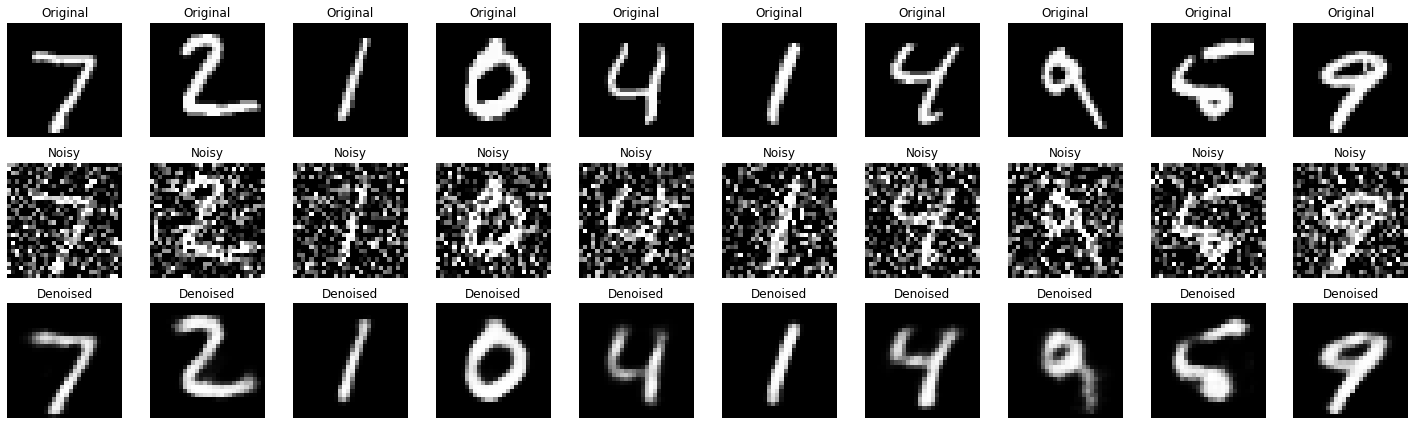

In [16]:
n = 10

plt.figure(figsize=(20,6))

for i in range(n):
    # Original Image
    ax = plt.subplot(3,n,i+1)
    plt.imshow(X_test[i].reshape(28,28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Noisy Image
    ax = plt.subplot(3,n,i+1+n)
    plt.imshow(X_test_noisy[i].reshape(28,28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Denoised Image
    ax = plt.subplot(3,n,i+1+2*n)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")
plt.tight_layout()
plt.show()


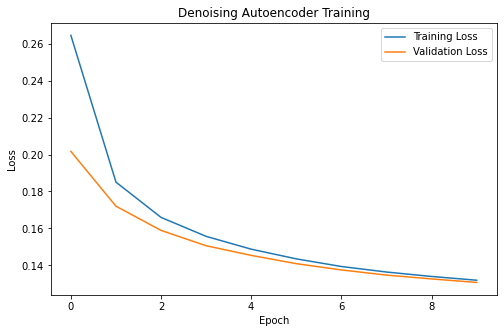

In [17]:
plt.figure(figsize=(8,5))
plt.plot(history_dae.history["loss"], label="Training Loss")
plt.plot(history_dae.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Denoising Autoencoder Training")
plt.legend()
plt.show()


In [19]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train, _), (X_test, _) = mnist.load_data()
X_train = X_train.astype("float32") / 255.
X_test = X_test.astype("float32") / 255.
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)
input_dim = 784
hidden_dim = 256
latent_dim = 2
inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(hidden_dim, activation="relu")(inputs)
z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon
z = Sampling()([z_mean, z_log_var])
encoder = Model(inputs, [z_mean, z_log_var, z])
encoder.summary()


Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_4 (InputLayer)        [(None, 784)]                0         []                            
                                                                                                  
 dense_15 (Dense)            (None, 256)                  200960    ['input_4[0][0]']             
                                                                                                  
 dense_16 (Dense)            (None, 2)                    514       ['dense_15[0][0]']            
                                                                                                  
 dense_17 (Dense)            (None, 2)                    514       ['dense_15[0][0]']            
                                                                                            

In [20]:
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(hidden_dim, activation="relu")(latent_inputs)
outputs = layers.Dense(
    input_dim,
    activation="sigmoid")(x)
decoder = Model(latent_inputs, outputs)
decoder.summary()


Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_5 (InputLayer)        [(None, 2)]               0         
                                                                 
 dense_18 (Dense)            (None, 256)               768       
                                                                 
 dense_19 (Dense)            (None, 784)               201488    
                                                                 
Total params: 202256 (790.06 KB)
Trainable params: 202256 (790.06 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Epoch 1/10
235/235 [==============================] - 2s 6ms/step - loss: 157.1694 - reconstruction_loss: 153.7816 - kl_loss: 3.3878
Epoch 2/10
235/235 [==============================] - 1s 6ms/step - loss: 156.3578 - reconstruction_loss: 152.9418 - kl_loss: 3.4160
Epoch 3/10
235/235 [==============================] - 1s 6ms/step - loss: 155.7695 - reconstruction_loss: 152.3244 - kl_loss: 3.4451
Epoch 4/10
235/235 [==============================] - 1s 6ms/step - loss: 155.0704 - reconstruction_loss: 151.5961 - kl_loss: 3.4743
Epoch 5/10
235/235 [==============================] - 2s 7ms/step - loss: 154.4722 - reconstruction_loss: 150.9706 - kl_loss: 3.5016
Epoch 6/10
235/235 [==============================] - 1s 6ms/step - loss: 153.9195 - reconstruction_loss: 150.4017 - kl_loss: 3.5178
Epoch 7/10
235/235 [==============================] - 2s 6ms/step - loss: 153.4556 - reconstruction_loss: 149.9259 - kl_loss: 3.5297
Epoch 8/10
235/235 [==============================] - 1s 5ms/step - l

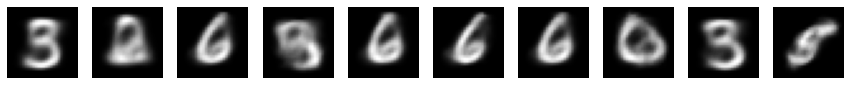

In [36]:
class VAE(Model):

    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        with tf.GradientTape() as tape:

            # Encode
            z_mean, z_log_var, z = self.encoder(data)

            # Decode
            reconstruction = self.decoder(z)

            # Reconstruction Loss
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    data,
                    reconstruction
                )
            ) * input_dim

            # KL Divergence Loss
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var)
            )

            # Total Loss
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(grads, self.trainable_weights)
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }
vae = VAE(encoder, decoder)

vae.compile(optimizer="adam")

history = vae.fit(
    X_train,
    epochs=10,
    batch_size=256
)
random_vector = tf.random.normal(shape=(10, latent_dim))

generated = decoder.predict(random_vector)

plt.figure(figsize=(15,3))

for i in range(10):
    plt.subplot(1,10,i+1)
    plt.imshow(generated[i].reshape(28,28), cmap="gray")
    plt.axis("off")

plt.show()


313/313 [==============================] - 1s 2ms/step


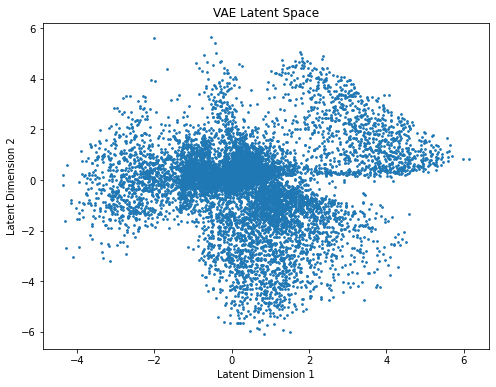

In [38]:
z_mean, _, _ = encoder.predict(X_test)

plt.figure(figsize=(8,6))
plt.scatter(z_mean[:,0], z_mean[:,1], s=3)
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space")
plt.show()


In [41]:
import pandas as pd

comparison = pd.DataFrame({

    "Model":[
        "Basic Autoencoder",
        "Denoising Autoencoder",
        "Variational Autoencoder"
    ],

    "Purpose":[
        "Compression & Feature Extraction",
        "Image Denoising",
        "Image Generation"
    ],

    "Latent Space":[
        "Deterministic",
        "Deterministic",
        "Probabilistic"
    ]

})
